# Classifying Aerosound

## (1) Aerosound

Import the data

In [113]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

In [26]:
import pandas as pd
#pd.set_option("display.max_columns", None)

#!curl -s https://wagon-public-datasets.s3.amazonaws.com/Machine%20Learning%20Datasets/ML_Electrocardiograms_dataset.csv > data/electrocardiograms.csv

data_ori = pd.read_csv('features_0dB.csv')

data_ori.head()

,noise,machine,id,label,file,snr,file_num,f_000,f_001,f_002,...,f_090,f_091,f_092,f_093,f_094,f_095,f_096,f_097,f_098,f_099
0,0_dB_fan,fan,id_06,normal,00000445.wav,0,445,0.007859,0.007273,0.007153,...,0.007396,0.006567,0.006378,0.006219,0.007189,0.006903,0.006694,0.006568,0.006612,0.006889
1,0_dB_fan,fan,id_06,normal,00000291.wav,0,291,0.007163,0.007749,0.007149,...,0.007496,0.006569,0.007258,0.007070,0.007413,0.007060,0.007191,0.007693,0.007572,0.007429
2,0_dB_fan,fan,id_06,normal,00000216.wav,0,216,0.007220,0.007008,0.007753,...,0.007419,0.007801,0.006783,0.006477,0.007118,0.007312,0.007311,0.006901,0.007797,0.007472
3,0_dB_fan,fan,id_06,normal,00000038.wav,0,38,0.007312,0.007044,0.008037,...,0.008527,0.008084,0.009099,0.008043,0.008936,0.007590,0.008123,0.007737,0.008308,0.008178
4,0_dB_fan,fan,id_06,normal,00000229.wav,0,229,0.006784,0.007067,0.008074,...,0.008380,0.007477,0.008079,0.007892,0.008239,0.008785,0.007579,0.006708,0.007315,0.008053


In [27]:
len(data_ori)

18019

In [120]:
data_ori['noise'].value_counts()

noise
0_dB_fan       5550
0_dB_pump      4205
0_dB_valve     4170
0_dB_slider    4094
Name: count, dtype: int64

In [121]:
data_ori['machine'].value_counts()

machine
fan       5550
pump      4205
valve     4170
slider    4094
Name: count, dtype: int64

In [28]:
data_ori.label.value_counts()

label
normal      14719
abnormal     3300
Name: count, dtype: int64

In [125]:
machine_dfs = {}

for machine in data_ori['machine'].unique():
    machine_dfs[machine] = data_ori[
        data_ori['machine'] == machine
    ].copy()

machine_dfs.keys()

dict_keys(['fan', 'pump', 'slider', 'valve'])

initialize the dataframe:

In [126]:
data = machine_dfs['fan'].copy()

💓 Each observation of the dataset is a sequence of measured sound

🎯 The target is binary and defines whether the machine is normal:
* abnormal 🔴 (1)
* or normal 🟢 (0)

In [127]:
data['label'] = data['label'].map({
    'normal': 0,
    'abnormal': 1
})
data.head()

,noise,machine,id,label,file,snr,file_num,f_000,f_001,f_002,...,f_090,f_091,f_092,f_093,f_094,f_095,f_096,f_097,f_098,f_099
0,0_dB_fan,fan,id_06,0,00000445.wav,0,445,0.007859,0.007273,0.007153,...,0.007396,0.006567,0.006378,0.006219,0.007189,0.006903,0.006694,0.006568,0.006612,0.006889
1,0_dB_fan,fan,id_06,0,00000291.wav,0,291,0.007163,0.007749,0.007149,...,0.007496,0.006569,0.007258,0.007070,0.007413,0.007060,0.007191,0.007693,0.007572,0.007429
2,0_dB_fan,fan,id_06,0,00000216.wav,0,216,0.007220,0.007008,0.007753,...,0.007419,0.007801,0.006783,0.006477,0.007118,0.007312,0.007311,0.006901,0.007797,0.007472
3,0_dB_fan,fan,id_06,0,00000038.wav,0,38,0.007312,0.007044,0.008037,...,0.008527,0.008084,0.009099,0.008043,0.008936,0.007590,0.008123,0.007737,0.008308,0.008178
4,0_dB_fan,fan,id_06,0,00000229.wav,0,229,0.006784,0.007067,0.008074,...,0.008380,0.007477,0.008079,0.007892,0.008239,0.008785,0.007579,0.006708,0.007315,0.008053


In [128]:
data = data.drop(columns=['noise','machine','id','file','snr','file_num'])
data = data.rename(columns={'label':'target'})
data.head()

,target,f_000,f_001,f_002,f_003,f_004,f_005,f_006,f_007,f_008,...,f_090,f_091,f_092,f_093,f_094,f_095,f_096,f_097,f_098,f_099
0,0,0.007859,0.007273,0.007153,0.007046,0.006933,0.006544,0.006407,0.006346,0.006663,...,0.007396,0.006567,0.006378,0.006219,0.007189,0.006903,0.006694,0.006568,0.006612,0.006889
1,0,0.007163,0.007749,0.007149,0.007188,0.007012,0.007063,0.007583,0.007343,0.007280,...,0.007496,0.006569,0.007258,0.007070,0.007413,0.007060,0.007191,0.007693,0.007572,0.007429
2,0,0.007220,0.007008,0.007753,0.007496,0.007751,0.007164,0.007296,0.006966,0.007199,...,0.007419,0.007801,0.006783,0.006477,0.007118,0.007312,0.007311,0.006901,0.007797,0.007472
3,0,0.007312,0.007044,0.008037,0.008222,0.007262,0.007793,0.008025,0.007310,0.006825,...,0.008527,0.008084,0.009099,0.008043,0.008936,0.007590,0.008123,0.007737,0.008308,0.008178
4,0,0.006784,0.007067,0.008074,0.008240,0.007917,0.007776,0.008585,0.007742,0.007976,...,0.008380,0.007477,0.008079,0.007892,0.008239,0.008785,0.007579,0.006708,0.007315,0.008053


## (2) Data Exploration

❓ **Question** ❓

Plot an observation of each target class to get a visual idea of what the numbers represent.

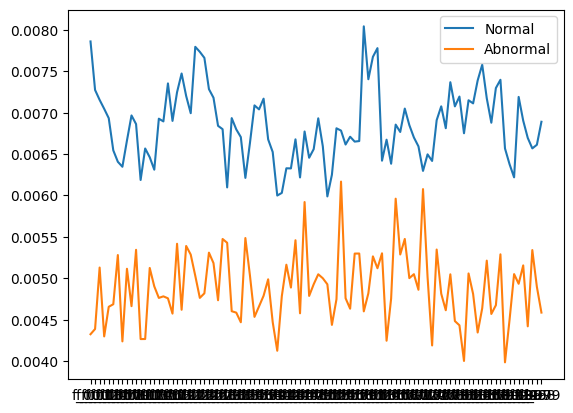

In [129]:
obser_0 = data[data['target']==0].drop(columns='target').iloc[0]
obser_1 = data[data['target']==1].drop(columns='target').iloc[0]

plt.figure()
plt.plot(obser_0, label='Normal')
plt.plot(obser_1,label='Abnormal')

plt.legend()
plt.show()


##  (3) Logistic Regression

🎯 Your task is to **flag machine sound sample that are abnormal.**

👇 Start by investigating the performance of a `LogisticRegression` on that task. Use a ***cross-validation to evaluate the model*** on the following metrics:
- Accuracy
- Recall
- Precision
- F1

In [130]:
X = data.drop(columns = 'target')
y = data['target']
model = LogisticRegression()

In [131]:
cv_result = cross_validate(
    model,
    X,
    y,
    cv = 5,
    scoring = ['accuracy','recall','precision','f1']
)
cv_result

/Users/shaotongwang/.pyenv/versions/3.10.6/envs/aerosound/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shaotongwang/.pyenv/versions/3.10.6/envs/aerosound/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/shaotongwang/.pyenv/versions/3.10.6/envs/aerosound/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavio

{'fit_time': array([0.03077197, 0.00343132, 0.00313115, 0.00471592, 0.00297689]),
 'score_time': array([0.00513482, 0.00396872, 0.00460291, 0.00379896, 0.00390577]),
 'test_accuracy': array([0.73423423, 0.73423423, 0.73423423, 0.73423423, 0.73423423]),
 'test_recall': array([0., 0., 0., 0., 0.]),
 'test_precision': array([0., 0., 0., 0., 0.]),
 'test_f1': array([0., 0., 0., 0., 0.])}

In [132]:
recall = cv_result['test_recall'].mean()
recall

np.float64(0.0)

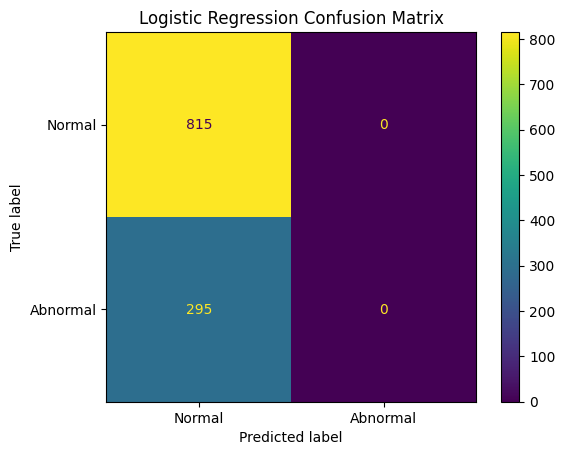

In [133]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

ConfusionMatrixDisplay.from_estimator(
    log_reg,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## (4) KNN Classifier

Print out a [`classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) of the KNN model.

In [134]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.82      0.91      0.86       815
           1       0.64      0.45      0.53       295

    accuracy                           0.79      1110
   macro avg       0.73      0.68      0.70      1110
weighted avg       0.77      0.79      0.77      1110



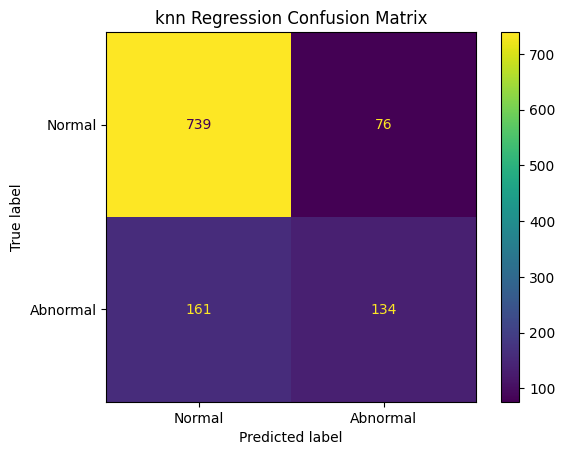

In [135]:
ConfusionMatrixDisplay.from_estimator(
    knn,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("knn Regression Confusion Matrix")
plt.show()

## (5) balance the data

oversampling abnormal sample x4

In [136]:
Train = X_train.copy()
Train['target'] = y_train
normal = Train[Train['target']==0]
abnormal = Train[Train['target']==1]
abnormal_4x = pd.concat([abnormal,abnormal,abnormal,abnormal])
train_balanced = pd.concat([normal,abnormal_4x])
train_balanced = train_balanced.sample(
    frac=1, random_state=42
).reset_index(drop=True)

train_balanced['target'].value_counts()


target
1    4720
0    3260
Name: count, dtype: int64

In [137]:
X_train_balanced = train_balanced.drop(columns='target')
y_train_balanced = train_balanced['target']

In [138]:
knn_balanced_trained = KNeighborsClassifier()
knn_balanced_trained.fit(X_train_balanced, y_train_balanced)
y_pred_balanced = knn_balanced_trained.predict(X_test)
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.84      0.56      0.67       815
           1       0.37      0.70      0.48       295

    accuracy                           0.60      1110
   macro avg       0.60      0.63      0.58      1110
weighted avg       0.71      0.60      0.62      1110



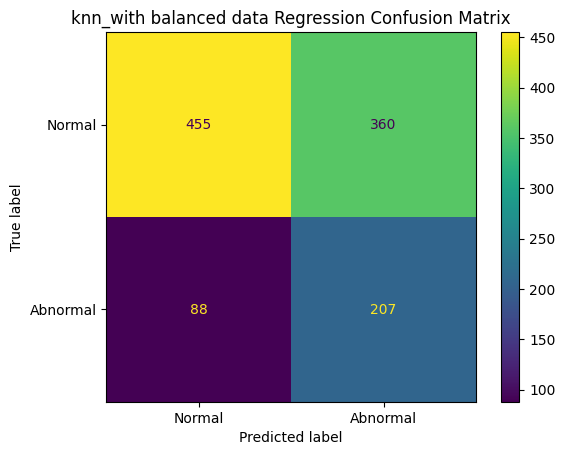

In [139]:
ConfusionMatrixDisplay.from_estimator(
    knn_balanced_trained,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("knn_with balanced data Regression Confusion Matrix")
plt.show()

 ## short conclution 

before making the data balance, the model find out 134/295 (45.4%) abnormal machine

after making the data balance, the model find out 207/295 (70.2%) abnormal machine

## (6) hyper parameters

In [140]:
knn_hp = KNeighborsClassifier()
param_grid = {
    'n_neighbors': [2, 3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid = GridSearchCV(
    knn_hp,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [141]:
grid.fit(X_train_balanced, y_train_balanced)

,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': [2, 3, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,2


In [142]:
grid.best_score_

np.float64(0.9251736407922454)

In [143]:
grid.best_params_

{'n_neighbors': 2, 'p': 2, 'weights': 'distance'}

In [144]:
knn_best = grid.best_estimator_

## (7) Best knn model

In [145]:
y_pred_best = knn_best.predict(X_test)
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.82      0.81      0.81       815
           1       0.49      0.51      0.50       295

    accuracy                           0.73      1110
   macro avg       0.65      0.66      0.66      1110
weighted avg       0.73      0.73      0.73      1110



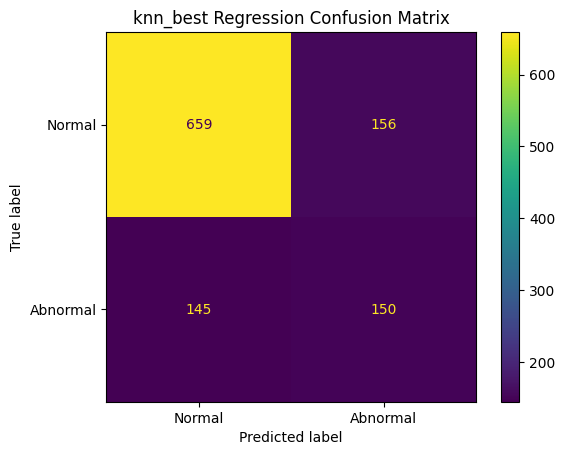

In [146]:
ConfusionMatrixDisplay.from_estimator(
    knn_best,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("knn_best Regression Confusion Matrix")
plt.show()

## balancing data caused the leakage, so I will redo the grid seach with origianl data

In [147]:
knn_hp2 = KNeighborsClassifier()
param_grid = {
    'n_neighbors': [2, 3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid2 = GridSearchCV(
    knn_hp,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [148]:
grid2.fit(X_train, y_train)

,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': [2, 3, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,7


In [149]:
print(grid2.best_score_)
print(grid2.best_params_)
knn_best2 = grid2.best_estimator_

0.5698325194644704
{'n_neighbors': 7, 'p': 1, 'weights': 'uniform'}


In [150]:
y_pred_best = knn_best2.predict(X_test)
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87       815
           1       0.66      0.44      0.53       295

    accuracy                           0.79      1110
   macro avg       0.74      0.68      0.70      1110
weighted avg       0.78      0.79      0.78      1110



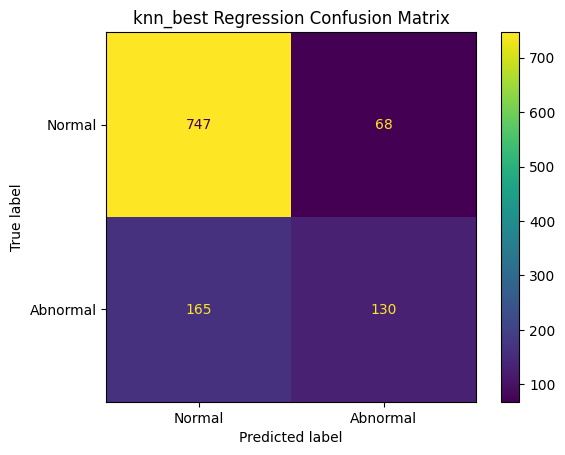

In [151]:
ConfusionMatrixDisplay.from_estimator(
    knn_best2,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("knn_best Regression Confusion Matrix")
plt.show()

## (8) Make pipeline to avoid leakage when useing oversampling data

In [156]:
# Step 1: Create pipeline
pipeline = Pipeline([
    ('oversampler', RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ('knn', KNeighborsClassifier())
])

# Step 2: Define hyperparameters
param_grid = {
    'knn__n_neighbors': [2, 3, 5, 7, 9, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# Step 3: GridSearchCV
grid3 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

# Step 4: Fit original training data
grid3.fit(X_train, y_train)

# Step 5: Results
print("Best parameters:", grid3.best_params_)
print("Best CV F1:", grid3.best_score_)

Best parameters: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
Best CV F1: 0.6754237288135594


In [157]:
knn_best3 = grid3.best_estimator_

In [158]:
y_pred_best = knn_best3.predict(X_test)
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.83      0.65      0.73       815
           1       0.40      0.64      0.49       295

    accuracy                           0.65      1110
   macro avg       0.62      0.64      0.61      1110
weighted avg       0.72      0.65      0.67      1110



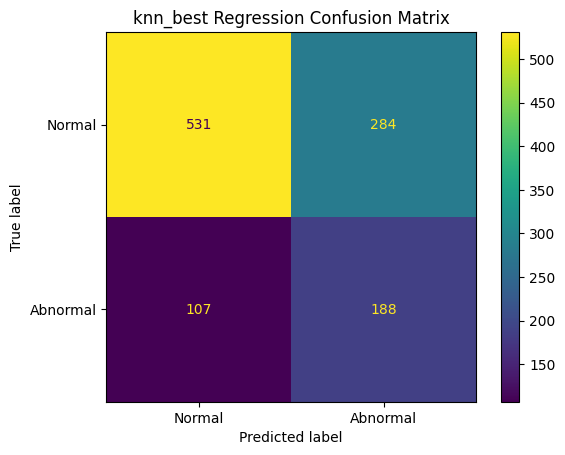

In [159]:
ConfusionMatrixDisplay.from_estimator(
    knn_best3,
    X_test,
    y_test,
    display_labels=["Normal", "Abnormal"]
)

plt.title("knn_best Regression Confusion Matrix")
plt.show()